In [37]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.model_selection import train_test_split

import nltk

from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud
from nltk.corpus import stopwords
lemmatizer = WordNetLemmatizer()
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score ,
    confusion_matrix , 
    ConfusionMatrixDisplay
)

In [2]:
dataset = load_dataset("fancyzhx/ag_news")


train_df = dataset["train"].to_pandas()


sample_df = (
    train_df
    .groupby("label", group_keys=False)
    .sample(n=1000, random_state=42)
)

print(sample_df.shape)

(4000, 2)


In [4]:
def clean_text(text):
    # Replace missing values with empty strings
    text = text.fillna("")

    # Normalize casing
    text = text.str.lower()

    # Remove punctuation
    text = text.str.replace(r'[^\w\s]', '', regex=True)

    # Remove numbers
    text = text.str.replace(r'\d+', '', regex=True)

    # Normalize whitespace
    text = text.str.replace(r'\s+', ' ', regex=True).str.strip()

    # Remove English stopwords
    sw = set(stopwords.words("english"))
    text = text.apply(
        lambda x: " ".join(
            word for word in x.split()
            if word not in sw
        )
    )

    # Remove words that occur only once in the corpus
    temp_df = pd.Series(" ".join(text).split()).value_counts()
    drops = temp_df[temp_df <= 1].index
    text = text.apply(
        lambda x: " ".join(
            word for word in x.split()
            if word not in drops
        )
    )

    # Lemmatize tokens
    text = text.apply(
        lambda x: " ".join(
            lemmatizer.lemmatize(word)
            for word in x.split()
        )
    )

    return text


sample_df["text"] = clean_text(sample_df["text"])

In [5]:
train_split_df, val_split_df = train_test_split(
    sample_df,
    test_size=0.20,
    stratify=sample_df["label"],
    random_state=42
)

print("Training:", train_split_df.shape)
print("Validation:", val_split_df.shape)

Training: (3200, 2)
Validation: (800, 2)


In [7]:
print(
    "Ortak haber sayısı:",
    val_split_df["text"].isin(train_split_df["text"]).sum()
)

Ortak haber sayısı: 0


In [25]:
# Training sınıf dağılımı
print("Training:")
print(train_split_df["label"].value_counts())

# Validation sınıf dağılımı
print("\nValidation:")
print(val_split_df["label"].value_counts())

Training:
label
3    800
2    800
0    800
1    800
Name: count, dtype: int64

Validation:
label
0    200
1    200
3    200
2    200
Name: count, dtype: int64


In [26]:
from pathlib import Path


data_dir = Path("../data")
data_dir.mkdir(parents=True, exist_ok=True)


train_split_df.to_csv(data_dir / "train_split.csv", index=False)
val_split_df.to_csv(data_dir / "val_split.csv", index=False)

print("Training ve Validation dosyaları kaydedildi.")

print("Training:", (data_dir / "train_split.csv").exists())
print("Validation:", (data_dir / "val_split.csv").exists())

Training ve Validation dosyaları kaydedildi.
Training: True
Validation: True


In [27]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    lowercase=True
)

In [28]:

model = LogisticRegression(
    max_iter=1000
)

In [29]:
pipeline = Pipeline([
    ("tfidf", tfidf),
    ("classifier", model)
])

In [30]:
pipeline.fit(
    train_split_df["text"],
    train_split_df["label"]
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",5000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


In [31]:
y_pred = pipeline.predict(
    val_split_df["text"]
)

print("Tahmin sayısı:", len(y_pred))
print("İlk 10 tahmin:", y_pred[:10])

Tahmin sayısı: 800
İlk 10 tahmin: [3 1 0 1 0 0 2 2 1 0]


In [33]:
y_val = val_split_df["label"]


y_pred = pipeline.predict(val_split_df["text"])


accuracy = accuracy_score(y_val, y_pred)

macro_precision = precision_score(
    y_val, y_pred, average="macro"
)

macro_recall = recall_score(
    y_val, y_pred, average="macro"
)

macro_f1 = f1_score(
    y_val, y_pred, average="macro"
)


print("=== TF-IDF + Logistic Regression Baseline ===")
print(f"Accuracy        : {accuracy:.4f}")
print(f"Macro Precision : {macro_precision:.4f}")
print(f"Macro Recall    : {macro_recall:.4f}")
print(f"Macro-F1        : {macro_f1:.4f}")

=== TF-IDF + Logistic Regression Baseline ===
Accuracy        : 0.8712
Macro Precision : 0.8719
Macro Recall    : 0.8712
Macro-F1        : 0.8711


In [35]:
cm = confusion_matrix(y_val, y_pred)

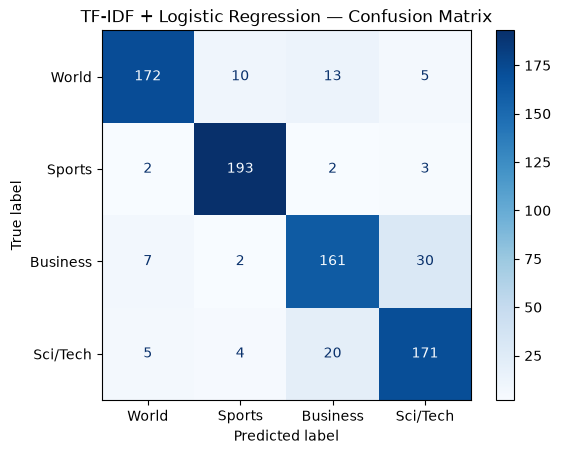

In [38]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["World", "Sports", "Business", "Sci/Tech"]
).plot(cmap="Blues")

plt.title("TF-IDF + Logistic Regression — Confusion Matrix")
plt.show()

In [40]:
expected_labels = {0, 1, 2, 3}

assert set(train_split_df["label"]) == expected_labels
assert set(val_split_df["label"]) == expected_labels
print("Test 1 PASSED: All four classes are present.")

assert train_split_df.index.intersection(val_split_df.index).empty

def normalize_text(series):
    return (
        series.astype("string")
        .str.normalize("NFKC")
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

train_texts = set(normalize_text(train_split_df["text"]))
val_texts = set(normalize_text(val_split_df["text"]))

assert train_texts.isdisjoint(val_texts)
print("Test 2 PASSED: No data leakage detected.")

tfidf_vectorizer = pipeline.named_steps["tfidf"]

X_train_tfidf = tfidf_vectorizer.transform(train_split_df["text"])
X_val_tfidf = tfidf_vectorizer.transform(val_split_df["text"])

assert X_train_tfidf.shape[1] == X_val_tfidf.shape[1]
print("Test 3 PASSED: TF-IDF feature dimensions match.")

print("\nTraining TF-IDF Shape:", X_train_tfidf.shape)
print("Validation TF-IDF Shape:", X_val_tfidf.shape)
print("\nALL TESTS PASSED")

Test 1 PASSED: All four classes are present.
Test 2 PASSED: No data leakage detected.
Test 3 PASSED: TF-IDF feature dimensions match.

Training TF-IDF Shape: (3200, 5000)
Validation TF-IDF Shape: (800, 5000)

ALL TESTS PASSED
